# 4.0 Evaluación de modelos de demanda

Compara las corridas del experimento `MiBici_Fase2_Modelos` con las funciones de `mibici_mlops.modeling.evaluate` y `compare`. Las líneas base fijan la referencia; cada modelo que registre el ML engineer aparece aquí al volver a ejecutar el notebook.

In [1]:
import mlflow
import pandas as pd
from IPython.display import Image, display
from loguru import logger

from mibici_mlops.config import (
    EXPERIMENT_MODELS, FIGURES_DIR, MLFLOW_TRACKING_URI, REPORTS_DIR, SELECTION_METRIC,
    TARGET_IMPROVEMENT_PCT,
)
from mibici_mlops.modeling.compare import comparison_table, load_runs, select_best

logger.disable('mibici_mlops')
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
tabla = comparison_table(load_runs(EXPERIMENT_MODELS))
cols = ['tipo', 'modelo', 'salidas_mae', 'salidas_mae_pico', 'salidas_rmse',
        'salidas_poisson', 'mejora_vs_base_pct', 'cumple_meta']
tabla[cols].round(3)

/home/fgrodriguez/mibici-mlops/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-07 12:36:21.038 | INFO     | mibici_mlops.config:<module>:12 - PROJ_ROOT path is: /home/fgrodriguez/mibici-mlops


,tipo,modelo,salidas_mae,salidas_mae_pico,salidas_rmse,salidas_poisson,mejora_vs_base_pct,cumple_meta
0,linea_base,promedio_historico,0.856,1.469,1.546,1.089,0.0,False
1,linea_base,misma_hora_semana_pasada,0.990,1.608,1.909,5.871,-9.5,False


El criterio de selección es el MAE de salidas en horas pico laborales (`SELECTION_METRIC`), porque ahí se decide la redistribución. La meta inicial del ML Canvas es reducirlo al menos un 15 % frente a la mejor línea base.

In [2]:
mejor = select_best(tabla)
print('Mejor corrida:', mejor['modelo'], mejor['run_id'])
print(f"{SELECTION_METRIC} = {mejor[SELECTION_METRIC]:.3f}; meta: {TARGET_IMPROVEMENT_PCT:g} %")

Mejor corrida: promedio_historico e2e2859c3f774ee986e12fb1d49d55c3
salidas_mae_pico = 1.469; meta: 15 %


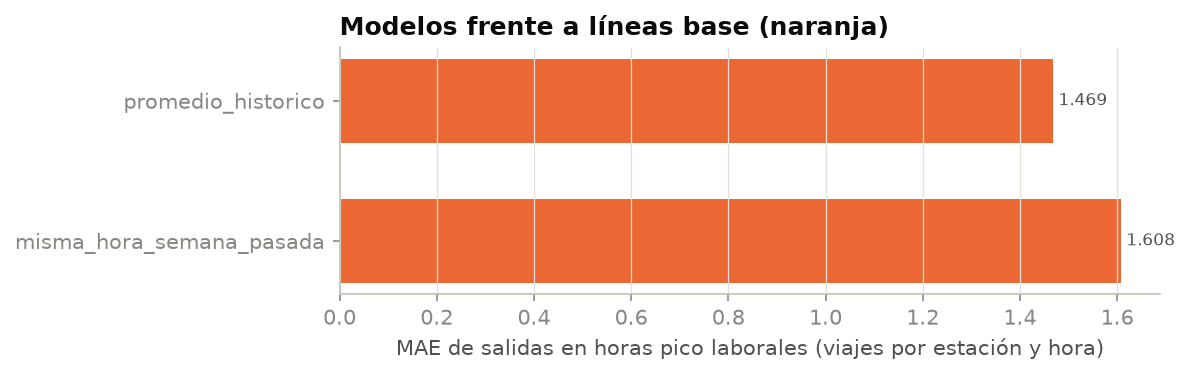

In [3]:
display(Image(FIGURES_DIR / '13_comparacion_modelos.png'))

## Dónde se equivoca

Error por hora y por segmento de estación (uso bajo, medio, alto).

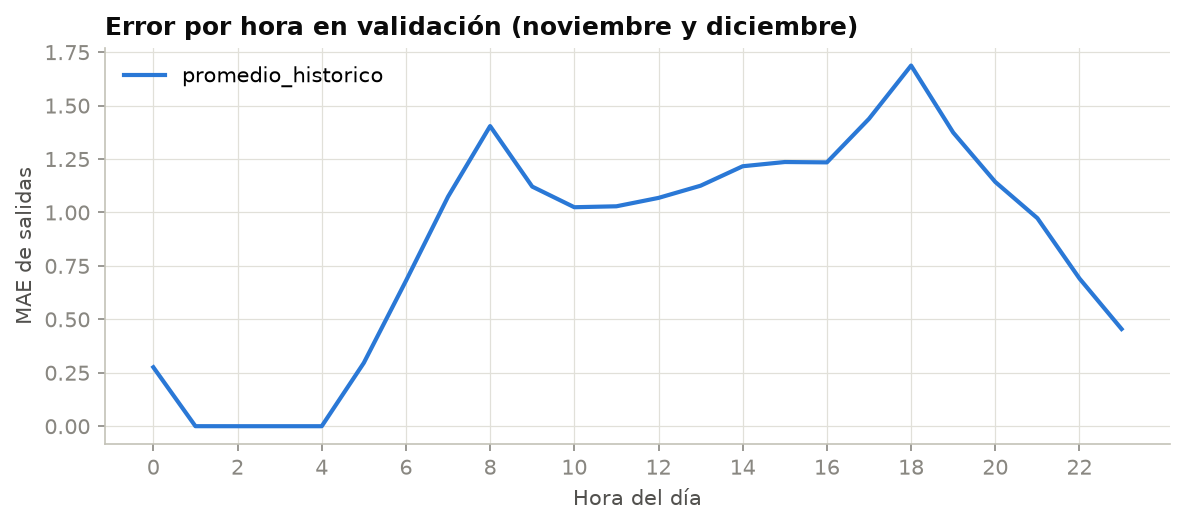

In [4]:
display(Image(FIGURES_DIR / '14_error_por_hora.png'))

In [5]:
diag = pd.read_csv(REPORTS_DIR / 'diagnostico_error.csv')
diag[diag['corte'] == 'segmento'][['modelo', 'segmento', 'mae']].round(3)

,modelo,segmento,mae
24,promedio_historico,alta,1.376
25,promedio_historico,baja,0.431
26,promedio_historico,media,0.760


El error se concentra en las horas pico y en las estaciones de uso alto. Un modelo útil para la operación debe mejorar justo ahí, no solo en el promedio general.